In [76]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [77]:
import sys
sys.path.append("../src")

In [78]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import string
from plotters import plot_differentiation_tree

In [79]:
diff_T = nx.DiGraph()

diff_T.add_node("A", diff_time=None)

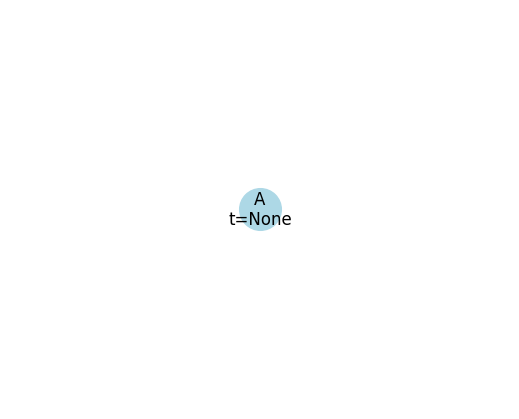

In [80]:
plot_differentiation_tree(diff_T)
# plt.show()

In [81]:
from simulator import load_tree

In [82]:
T, root = load_tree("../data/simulation/test/T_extant.json")

In [83]:
for u, v, data in T.edges(data=True):
    print(f"{u} -> {v} : {data}")

0 -> 1 : {'start_time': 0.0, 'end_time': 0.11304925204928948, 'length': 0.11304925204928948}
1 -> 2 : {'start_time': 0.11304925204928948, 'end_time': 0.13177407073764083, 'length': 0.018724818688351352}
1 -> 9 : {'start_time': 0.11304925204928948, 'end_time': 0.5780089202706781, 'length': 0.46495966822138857}
2 -> 4 : {'start_time': 0.13177407073764083, 'end_time': 0.3849449712603159, 'length': 0.2531709005226751}
2 -> 5 : {'start_time': 0.13177407073764083, 'end_time': 0.16953781190137746, 'length': 0.037763741163736625}
4 -> 14 : {'start_time': 0.3849449712603159, 'end_time': 0.39751547464672393, 'length': 0.012570503386408027}
4 -> 15 : {'start_time': 0.3849449712603159, 'end_time': 0.6876782486522209, 'length': 0.30273327739190503}
5 -> 6 : {'start_time': 0.16953781190137746, 'end_time': 0.2379804994529762, 'length': 0.06844268755159874}
5 -> 7 : {'start_time': 0.16953781190137746, 'end_time': 0.5145921584717951, 'length': 0.3450543465704176}
6 -> 11 : {'start_time': 0.237980499452

In [84]:
cell_lineage_T = nx.DiGraph()

for u, v, data in T.edges(data=True):
    cell_lineage_T.add_edge(u, v, weight=data['length'])
    if 'end_time' in data and data['end_time'] == 1:
        cell_lineage_T.nodes[v]['type'] = "A"

In [85]:
from plotters import draw_ultrametric_tree

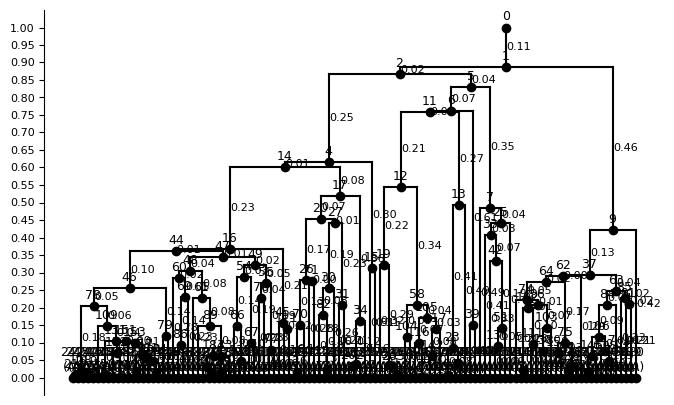

In [86]:
draw_ultrametric_tree(cell_lineage_T, root=root, diff_T=diff_T)

In [87]:
def add_node_times(cell_lineage_T, root=0):
    distances = nx.single_source_dijkstra_path_length(cell_lineage_T, root, weight='weight')
    for node, dist in distances.items():
        cell_lineage_T.nodes[node]['T'] = 1 - dist
    
    return cell_lineage_T

cell_lineage_T = add_node_times(cell_lineage_T)

In [88]:
from likelihood import type_internal_nodes

In [89]:
cell_lineage_T = type_internal_nodes(cell_lineage_T, diff_T)

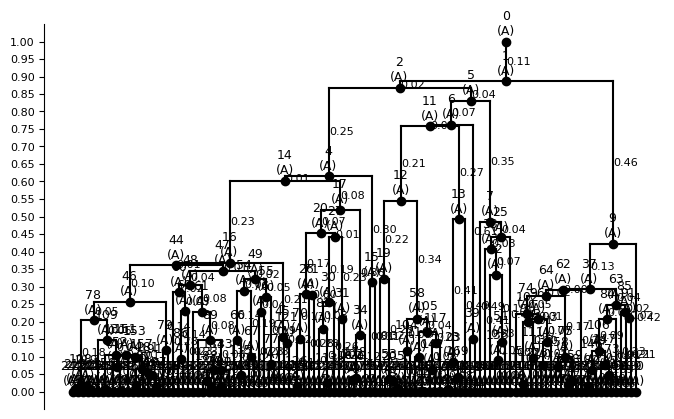

In [90]:
draw_ultrametric_tree(cell_lineage_T, root=0, diff_T=diff_T)

In [91]:
from likelihood import calculate_likelihood

In [92]:
birth_rates = {"A": .4}
death_rates = {"A": 0.2}

calculate_likelihood(
    birth_rates=birth_rates,
    death_rates=death_rates,
    transition_probabilities=None,
    cell_lineage_T=cell_lineage_T,
    diff_T=diff_T
)

4.3416229463867514e-51

In [93]:
import numpy as np


def likelihood_grid(
    birth_grid,
    death_grid,
    cell_lineage_T,
    diff_T
):
    """
    Compute likelihoods over a grid of birth/death rates.
    """

    L = np.zeros((len(death_grid), len(birth_grid)))

    for i, lam in enumerate(birth_grid):
        for j, mu in enumerate(death_grid):
            birth_rates = {"A": lam}
            death_rates = {"A": mu}

            L[j, i] = calculate_likelihood(
                birth_rates=birth_rates,
                death_rates=death_rates,
                transition_probabilities=None,
                cell_lineage_T=cell_lineage_T,
                diff_T=diff_T
            )

    return L


In [94]:
import matplotlib.pyplot as plt


def plot_likelihood_surface(birth_grid, death_grid, L):
    plt.figure(figsize=(6, 5))

    plt.imshow(
        L,
        origin="lower",
        extent=[
            birth_grid.min(), birth_grid.max(),
            death_grid.min(), death_grid.max(),

        ],
        aspect="auto"
    )

    plt.ylabel("Death rate μ")
    plt.xlabel("Birth rate λ")
    plt.colorbar(label="Probability P")
    plt.tight_layout()
    plt.show()

/Users/samin/workspace/phylodynamic-carta/notebooks/../src/likelihood.py:12: RuntimeWarning: invalid value encountered in scalar divide
  ):
/Users/samin/workspace/phylodynamic-carta/notebooks/../src/likelihood.py:42: RuntimeWarning: invalid value encountered in scalar divide
  exp( -(birth_rates[child] - death_rates[child]) *
/Users/samin/workspace/phylodynamic-carta/notebooks/../src/likelihood.py:42: RuntimeWarning: divide by zero encountered in scalar divide
  exp( -(birth_rates[child] - death_rates[child]) *
/Users/samin/workspace/phylodynamic-carta/notebooks/../src/likelihood.py:12: RuntimeWarning: divide by zero encountered in scalar divide
  ):
/Users/samin/workspace/phylodynamic-carta/notebooks/../src/likelihood.py:67: RuntimeWarning: invalid value encountered in scalar divide
  


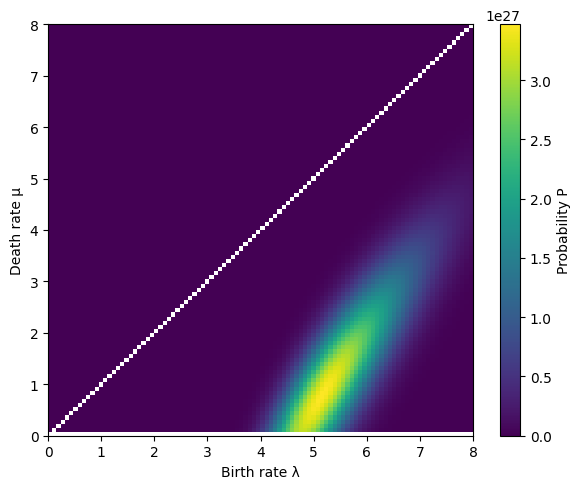

In [95]:
birth_grid = np.linspace(0.0, 8.0, 100)
death_grid = np.linspace(0.0, 8.0, 100)

L = likelihood_grid(
    birth_grid,
    death_grid,
    cell_lineage_T=cell_lineage_T,
    diff_T=diff_T
)
# print(L)
plot_likelihood_surface(birth_grid, death_grid, L)
